# Experiment A — Improved Tier-2 Precision/Recall Optimization (VALIDATION ONLY)

This notebook searches the finalized Tier-2 operating space for an **improved** configuration.
The frozen baseline (HTTP-only HC @ 0.50, weights 60/20/10/10, corr @ 0.22) is NOT modified —
it is the reference. All threshold/weight selection uses the **validation** split; the held-out
test set is touched only once, after the improved configuration is frozen.

**Why PR-AUC matters here:** the insider-threat dataset is severely imbalanced (201 malicious
out of 61,203 test rows). ROC-AUC can look high while precision at the operating point is poor.
Average Precision / PR-AUC directly reflects precision across recall levels, so it is the more
honest summary for this problem.

**Selection criterion (main):** maximize **Precision** subject to **Recall ≥ 0.85**.
Also reported: best Precision s.t. Recall ≥ 0.90, and best F1.

## 1. Baseline documentation (read-only inputs)

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

_curr = Path.cwd()
while not (_curr / 'pyproject.toml').exists() and _curr != _curr.parent:
    _curr = _curr.parent
PROJECT_ROOT = _curr
sys.path.insert(0, str(PROJECT_ROOT / 'week4' / 'improved_model'))

import improved_config as C
from improved_config import (metrics_from, orchestrator_decision, weighted_risk,
                             BASELINE_HC_THRESHOLD, BASELINE_CORR_WEIGHTS,
                             BASELINE_CORR_THRESHOLD)

print('=== BASELINE (frozen) ===')
print(f'  HTTP HC threshold     = {BASELINE_HC_THRESHOLD}')
print(f'  Correlation weights   = {BASELINE_CORR_WEIGHTS}')
print(f'  Correlation threshold = {BASELINE_CORR_THRESHOLD}')
base_t2 = pd.read_csv(C.BASELINE_T2_PREDICTIONS)
print(f'  Baseline Tier-2 test metrics:')
print('   ', metrics_from(base_t2))

print('\nFiles used as read-only inputs (NOT modified):')
print(f'  {C.BASELINE_T2_PREDICTIONS}')
print(f'  {C.VALIDATION_SCORES}')
print(f'  {C.TEST_SCORES}')
print(f'  {C.BASELINE_T3_TRIAGE}')
print('\nArchitecture preserved: Tier-1 scores -> Tier-2 gating -> escalate -> Tier-3.')

# --- load validation + test (test kept separate; not used for selection) ---
df_val = pd.read_csv(C.VALIDATION_SCORES)
df_test = pd.read_csv(C.TEST_SCORES)
print(f'\nValidation: {len(df_val):,} rows, {df_val["user"].nunique()} users, {int(df_val["label"].sum())} positives')
print(f'Test:       {len(df_test):,} rows, {df_test["user"].nunique()} users, {int(df_test["label"].sum())} positives')
assert len(set(df_val['user']) & set(df_test['user'])) == 0, 'val/test user overlap!'

=== BASELINE (frozen) ===
  HTTP HC threshold     = 0.5
  Correlation weights   = {'http': 0.6, 'file_device': 0.2, 'logon': 0.1, 'email': 0.1}
  Correlation threshold = 0.22
  Baseline Tier-2 test metrics:
    {'recall': 0.9054726368159204, 'precision': 0.1338235294117647, 'fpr': 0.01931084226746664, 'f1': 0.23318385650224216, 'roc_auc': 0.9845065841573418, 'pr_auc': 0.590343515637001, 'tp': 182, 'fp': 1178, 'fn': 19, 'tn': 59824, 'escalated': 1360, 'escalation_rate': 0.022221132950999135, 'n_rows': 61203}

Files used as read-only inputs (NOT modified):
  C:\insider_threat_detection_project2\week3\tier2_orchestrator_test_predictions.csv
  C:\insider_threat_detection_project2\week3\tier1_validation_scores.csv
  C:\insider_threat_detection_project2\week3\tier1_test_scores.csv
  C:\insider_threat_detection_project2\week4\llm_triage_output.csv

Architecture preserved: Tier-1 scores -> Tier-2 gating -> escalate -> Tier-3.

Validation: 61,076 rows, 200 users, 191 positives
Test:       61,20

## 2. Baseline validation metrics (reference point)

In [2]:
base_val = orchestrator_decision(df_val, BASELINE_HC_THRESHOLD,
                                  BASELINE_CORR_WEIGHTS, BASELINE_CORR_THRESHOLD)
base_val_m = metrics_from(base_val)
display(Markdown('### Baseline Tier-2 on VALIDATION'))
display(pd.DataFrame([base_val_m]).round(4))

### Baseline Tier-2 on VALIDATION

,recall,precision,fpr,f1,roc_auc,pr_auc,tp,fp,fn,tn,escalated,escalation_rate,n_rows
0,0.9843,0.1905,0.0131,0.3192,0.996,0.6249,188,799,3,60086,987,0.0162,61076


## 3. Grid search over Tier-2 operating points (validation only)

In [3]:
# --- candidate grids (validation only) ---
hc_grid = [0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]
corr_thr_grid = [0.18, 0.20, 0.22, 0.24, 0.26, 0.28, 0.30]
weight_configs = {
    'A (60/20/10/10)': {'http': 0.60, 'file_device': 0.20, 'logon': 0.10, 'email': 0.10},
    'B (50/25/15/10)': {'http': 0.50, 'file_device': 0.25, 'logon': 0.15, 'email': 0.10},
    'C (50/20/15/15)': {'http': 0.50, 'file_device': 0.20, 'logon': 0.15, 'email': 0.15},
    'D (55/20/15/10)': {'http': 0.55, 'file_device': 0.20, 'logon': 0.15, 'email': 0.10},
    'E (55/25/10/10)': {'http': 0.55, 'file_device': 0.25, 'logon': 0.10, 'email': 0.10},
}
for name, w in weight_configs.items():
    assert abs(sum(w.values()) - 1.0) < 1e-9, f'{name}: weights must sum to 1'

rows = []
for wname, w in weight_configs.items():
    for hc_t in hc_grid:
        for corr_t in corr_thr_grid:
            d = orchestrator_decision(df_val, hc_t, w, corr_t)
            m = metrics_from(d)
            rows.append({'weight_config': wname, 'hc_threshold': hc_t,
                         'corr_threshold': corr_t, **m})

grid = pd.DataFrame(rows)
print(f'Grid size: {len(grid)} configurations (validation-only evaluation)')
C.save_output(grid, C.T2_THRESHOLD_GRID)

# also save the weight grid separately
wgrid = pd.DataFrame([{'weight_config': n, **w} for n, w in weight_configs.items()])
C.save_output(wgrid, C.T2_WEIGHT_GRID)

Grid size: 245 configurations (validation-only evaluation)
Saved: C:\insider_threat_detection_project2\week4\improved_model\outputs\tier2_threshold_grid.csv (245 rows)
Saved: C:\insider_threat_detection_project2\week4\improved_model\outputs\tier2_weight_grid.csv (5 rows)


## 4. Selection: max Precision s.t. Recall ≥ 0.85 (validation)

In [4]:
# Main criterion: maximize Precision subject to Recall >= 0.85
cand_85 = grid[grid['recall'] >= 0.85].copy()
if len(cand_85):
    sel_85 = cand_85.loc[cand_85['precision'].idxmax()]
    print('[SELECTED] max Precision s.t. Recall >= 0.85 (validation):')
    print(f'  weight_config={sel_85["weight_config"]}  hc={sel_85["hc_threshold"]:.2f}  corr={sel_85["corr_threshold"]:.2f}')
    print(f'  Recall={sel_85["recall"]:.4f}  Precision={sel_85["precision"]:.4f}  FPR={sel_85["fpr"]:.4f}  '
          f'F1={sel_85["f1"]:.4f}  PR-AUC={sel_85["pr_auc"]:.4f}  escalated={int(sel_85["escalated"])}')
else:
    print('No config reaches Recall >= 0.85 on validation; using best recall.')
    sel_85 = grid.loc[grid['recall'].idxmax()]

# Secondary: best Precision s.t. Recall >= 0.90
cand_90 = grid[grid['recall'] >= 0.90].copy()
sel_90 = cand_90.loc[cand_90['precision'].idxmax()] if len(cand_90) else None
if sel_90 is not None:
    print('\n[SECONDARY] max Precision s.t. Recall >= 0.90:')
    print(f'  {sel_90["weight_config"]} hc={sel_90["hc_threshold"]:.2f} corr={sel_90["corr_threshold"]:.2f} '
          f'| Recall={sel_90["recall"]:.4f} Precision={sel_90["precision"]:.4f} FPR={sel_90["fpr"]:.4f}')

# Best F1
best_f1 = grid.loc[grid['f1'].idxmax()]
print('\n[BEST F1] (validation):')
print(f'  {best_f1["weight_config"]} hc={best_f1["hc_threshold"]:.2f} corr={best_f1["corr_threshold"]:.2f} '
      f'| Recall={best_f1["recall"]:.4f} Precision={best_f1["precision"]:.4f} F1={best_f1["f1"]:.4f}')

# Save validation results
grid.round(6).to_csv(C.T2_VALIDATION_RESULTS, index=False)
print(f'\nSaved validation results -> {C.T2_VALIDATION_RESULTS}')

[SELECTED] max Precision s.t. Recall >= 0.85 (validation):
  weight_config=C (50/20/15/15)  hc=0.60  corr=0.30
  Recall=0.9686  Precision=0.3073  FPR=0.0068  F1=0.4666  PR-AUC=0.6391  escalated=602

[SECONDARY] max Precision s.t. Recall >= 0.90:
  C (50/20/15/15) hc=0.60 corr=0.30 | Recall=0.9686 Precision=0.3073 FPR=0.0068

[BEST F1] (validation):
  C (50/20/15/15) hc=0.60 corr=0.30 | Recall=0.9686 Precision=0.3073 F1=0.4666

Saved validation results -> C:\insider_threat_detection_project2\week4\improved_model\outputs\tier2_validation_results.csv


## 5. Precision-Recall trade-off analysis (validation)

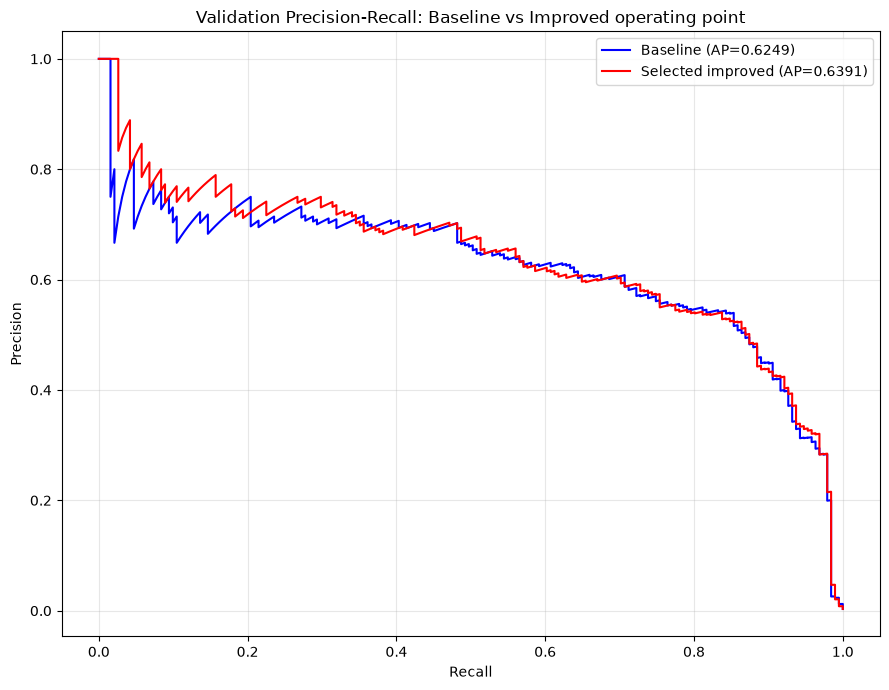

Validation AP: baseline=0.6249  selected=0.6391


In [5]:
# PR curve for the baseline config vs selected config on validation
from sklearn.metrics import precision_recall_curve, average_precision_score

def pr_curve(d, score_col='risk_score'):
    p, r, _ = precision_recall_curve(d['label'], d[score_col])
    ap = average_precision_score(d['label'], d[score_col])
    return p, r, ap

sel_w = weight_configs[sel_85['weight_config']]
sel_hc = float(sel_85['hc_threshold'])
sel_corr = float(sel_85['corr_threshold'])

base_v = orchestrator_decision(df_val, BASELINE_HC_THRESHOLD, BASELINE_CORR_WEIGHTS, BASELINE_CORR_THRESHOLD)
sel_v = orchestrator_decision(df_val, sel_hc, sel_w, sel_corr)

p_b, r_b, ap_b = pr_curve(base_v)
p_s, r_s, ap_s = pr_curve(sel_v)

fig, ax = plt.subplots(figsize=(9, 7))
ax.plot(r_b, p_b, 'b-', label=f'Baseline (AP={ap_b:.4f})')
ax.plot(r_s, p_s, 'r-', label=f'Selected improved (AP={ap_s:.4f})')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Validation Precision-Recall: Baseline vs Improved operating point')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('Validation AP: baseline={:.4f}  selected={:.4f}'.format(ap_b, ap_s))

## 6. Operating-point comparison on validation (baseline vs selected)

In [6]:
compare = pd.DataFrame({
    'Metric': ['Recall', 'Precision', 'FPR', 'F1', 'ROC-AUC', 'PR-AUC', 'Escalated', 'TP', 'FP', 'FN'],
    'Baseline': [base_val_m['recall'], base_val_m['precision'], base_val_m['fpr'], base_val_m['f1'],
                 base_val_m['roc_auc'], base_val_m['pr_auc'], base_val_m['escalated'],
                 base_val_m['tp'], base_val_m['fp'], base_val_m['fn']],
    'Selected': [sel_85['recall'], sel_85['precision'], sel_85['fpr'], sel_85['f1'],
                 sel_85['roc_auc'], sel_85['pr_auc'], sel_85['escalated'],
                 sel_85['tp'], sel_85['fp'], sel_85['fn']],
})
display(compare.round(4))

,Metric,Baseline,Selected
0,Recall,0.9843,0.9686
1,Precision,0.1905,0.3073
2,FPR,0.0131,0.0068
3,F1,0.3192,0.4666
4,ROC-AUC,0.9960,0.9956
5,PR-AUC,0.6249,0.6391
6,Escalated,987.0000,602.0000
7,TP,188.0000,185.0000
8,FP,799.0000,417.0000
9,FN,3.0000,6.0000


## 7. FREEZE the selected configuration + evaluate ONCE on held-out test

In [7]:
# FREEZE the improved configuration (selected on validation only)
IMPROVED_HC_THRESHOLD = sel_hc
IMPROVED_CORR_WEIGHTS = dict(sel_w)
IMPROVED_CORR_THRESHOLD = sel_corr

print('=' * 60)
print('  IMPROVED TIER-2 CONFIGURATION (frozen)')
print('=' * 60)
print(f'  HTTP HC threshold     = {IMPROVED_HC_THRESHOLD:.2f}')
print(f'  Correlation weights   = {IMPROVED_CORR_WEIGHTS}')
print(f'  Correlation threshold = {IMPROVED_CORR_THRESHOLD:.2f}')
print('=' * 60)

# Evaluate ONCE on the held-out test set (not used for selection)
df_test_imp = orchestrator_decision(df_test, IMPROVED_HC_THRESHOLD,
                                    IMPROVED_CORR_WEIGHTS, IMPROVED_CORR_THRESHOLD)
imp_test_m = metrics_from(df_test_imp)

print('\n--- IMPROVED TIER-2 ON HELD-OUT TEST ---')
print(f'  Recall={imp_test_m["recall"]:.4f}  Precision={imp_test_m["precision"]:.4f}  '
      f'FPR={imp_test_m["fpr"]:.4f}  F1={imp_test_m["f1"]:.4f}')
print(f'  ROC-AUC={imp_test_m["roc_auc"]:.4f}  PR-AUC={imp_test_m["pr_auc"]:.4f}')
print(f'  Escalated={imp_test_m["escalated"]}  TP={imp_test_m["tp"]}  FP={imp_test_m["fp"]}  '
      f'FN={imp_test_m["fn"]}  TN={imp_test_m["tn"]}')

# Save the improved Tier-2 test predictions (NEW file, never overwrites baseline)
C.save_output(df_test_imp, C.IMPROVED_T2_PREDICTIONS)
test_results = pd.DataFrame([{'config': 'improved', **imp_test_m}])
C.save_output(test_results, C.T2_TEST_RESULTS)

# Baseline test metrics for comparison
base_test_m = metrics_from(base_t2)
print('\n--- BASELINE ON HELD-OUT TEST (reference) ---')
print(f'  Recall={base_test_m["recall"]:.4f}  Precision={base_test_m["precision"]:.4f}  '
      f'FPR={base_test_m["fpr"]:.4f}  F1={base_test_m["f1"]:.4f}')
print(f'  ROC-AUC={base_test_m["roc_auc"]:.4f}  PR-AUC={base_test_m["pr_auc"]:.4f}')
print(f'  Escalated={base_test_m["escalated"]}  TP={base_test_m["tp"]}  FP={base_test_m["fp"]}  FN={base_test_m["fn"]}')

final_compare = pd.DataFrame({
    'Metric': ['Recall', 'Precision', 'FPR', 'F1', 'ROC-AUC', 'PR-AUC', 'Escalated', 'FP', 'TP', 'FN'],
    'Baseline': [base_test_m['recall'], base_test_m['precision'], base_test_m['fpr'], base_test_m['f1'],
                 base_test_m['roc_auc'], base_test_m['pr_auc'], base_test_m['escalated'],
                 base_test_m['fp'], base_test_m['tp'], base_test_m['fn']],
    'Improved': [imp_test_m['recall'], imp_test_m['precision'], imp_test_m['fpr'], imp_test_m['f1'],
                 imp_test_m['roc_auc'], imp_test_m['pr_auc'], imp_test_m['escalated'],
                 imp_test_m['fp'], imp_test_m['tp'], imp_test_m['fn']],
})
display(Markdown('### Final: Baseline vs Improved (held-out test)'))
display(final_compare.round(4))

  IMPROVED TIER-2 CONFIGURATION (frozen)
  HTTP HC threshold     = 0.60
  Correlation weights   = {'http': 0.5, 'file_device': 0.2, 'logon': 0.15, 'email': 0.15}
  Correlation threshold = 0.30

--- IMPROVED TIER-2 ON HELD-OUT TEST ---
  Recall=0.8856  Precision=0.2500  FPR=0.0088  F1=0.3899
  ROC-AUC=0.9829  PR-AUC=0.5878
  Escalated=712  TP=178  FP=534  FN=23  TN=60468
Saved: C:\insider_threat_detection_project2\week4\improved_model\outputs\improved_tier2_test_predictions.csv (61,203 rows)
Saved: C:\insider_threat_detection_project2\week4\improved_model\outputs\tier2_test_results.csv (1 rows)

--- BASELINE ON HELD-OUT TEST (reference) ---
  Recall=0.9055  Precision=0.1338  FPR=0.0193  F1=0.2332
  ROC-AUC=0.9845  PR-AUC=0.5903
  Escalated=1360  TP=182  FP=1178  FN=19


### Final: Baseline vs Improved (held-out test)

,Metric,Baseline,Improved
0,Recall,0.9055,0.8856
1,Precision,0.1338,0.2500
2,FPR,0.0193,0.0088
3,F1,0.2332,0.3899
4,ROC-AUC,0.9845,0.9829
5,PR-AUC,0.5903,0.5878
6,Escalated,1360.0000,712.0000
7,FP,1178.0000,534.0000
8,TP,182.0000,178.0000
9,FN,19.0000,23.0000


## 8. Reproducibility notes

In [8]:
print('Seed: deterministic grid search (no RNG involved in Tier-2 scoring).')
print('Configuration recorded:')
print(json := {'hc_threshold': IMPROVED_HC_THRESHOLD,
               'corr_weights': IMPROVED_CORR_WEIGHTS,
               'corr_threshold': IMPROVED_CORR_THRESHOLD,
               'selection': 'max precision s.t. recall>=0.85 (validation)',
               'validation_rows': len(df_val), 'test_rows': len(df_test)})
import json as _json
print(_json.dumps(json, indent=2))

Seed: deterministic grid search (no RNG involved in Tier-2 scoring).
Configuration recorded:
{'hc_threshold': 0.6, 'corr_weights': {'http': 0.5, 'file_device': 0.2, 'logon': 0.15, 'email': 0.15}, 'corr_threshold': 0.3, 'selection': 'max precision s.t. recall>=0.85 (validation)', 'validation_rows': 61076, 'test_rows': 61203}
{
  "hc_threshold": 0.6,
  "corr_weights": {
    "http": 0.5,
    "file_device": 0.2,
    "logon": 0.15,
    "email": 0.15
  },
  "corr_threshold": 0.3,
  "selection": "max precision s.t. recall>=0.85 (validation)",
  "validation_rows": 61076,
  "test_rows": 61203
}
